In [ ]:
import torch
import torch.nn as nn
import torchvision
import torch.nn.functional as F
import numpy as np
import pandas as pd
from torchvision import datasets, transforms, models, utils
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import matplotlib.pyplot as plt
import os
from functools import partial

In [ ]:
! pip install -q kaggle

In [ ]:
from google.colab import files

files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"beojkk","key":"f5032ed5341afd8bd1744192d3316d76"}'}

In [ ]:
!mkdir ./kaggle/

In [ ]:
! cp kaggle.json ~/.kaggle/
! chmod 600 ~/.kaggle/kaggle.json

https://www.kaggle.com/datasets/andrewmvd/animal-faces

In [ ]:
!kaggle datasets download -d andrewmvd/animal-faces

 99% 690M/696M [00:04<00:00, 200MB/s]
100% 696M/696M [00:04<00:00, 171MB/s]


In [ ]:
! mkdir dataset

In [ ]:
! unzip -qq animal-faces.zip -d dataset 

In [ ]:
data_dir = "/content/dataset/afhq/train"

train_transform = torchvision.transforms.Compose([transforms.ToTensor(),
                                                  transforms.Resize((32,32)),
                                                  transforms.RandomCrop(32),
                                                 ])

train_dataset = torchvision.datasets.ImageFolder(data_dir, transform = train_transform)

trainloader = partial(torch.utils.data.DataLoader,
    train_dataset, shuffle = True
)

K = len(set(train_dataset.targets))

In [ ]:
K

3

In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"

In [ ]:
class CNN(nn.Module):
    def __init__(self, K):
        super(CNN, self).__init__()
        
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),
        )
        
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2),
        )
        
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2),
        )
        
        self.fc1 = nn.Linear(128 * 4 * 4, 1024)
        self.fc2 = nn.Linear(1024, 512)
        self.fc3 = nn.Linear(512, K)
        
    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = x.view(x.size(0), -1)
        x = F.dropout(x, p=0.12)
        x = F.relu(self.fc1(x))
        x = F.dropout(x, p=0.8)
        x = F.relu(self.fc2(x))
        x = F.dropout(x, p=0.6)
        x = self.fc3(x)
        return x

In [ ]:
def train(model, lossfunction, optimizer, trainloader, epochs):
  for i in range(epochs):
    train_loss = []
    for inputs, targets in trainloader:
      inputs, targets = inputs.to(device), targets.to(device)
      optimizer.zero_grad()
      outputs = model(inputs)
      loss = lossfunction(outputs, targets)
      loss.backward()
      optimizer.step()
      train_loss.append(loss.item())

    train_loss = np.mean(train_loss)

    print(f'Epoch:{i+1}/{epochs}, Train Loss: {train_loss:.4f}')

In [ ]:
model = CNN(K)
model.to(device)

train(model, lossfunction=nn.CrossEntropyLoss(), optimizer=torch.optim.Adam(model.parameters()), trainloader=trainloader(batch_size=16), epochs=7)

Epoch:1/7, Train Loss: 0.5796
Epoch:2/7, Train Loss: 0.3255
Epoch:3/7, Train Loss: 0.2660
Epoch:4/7, Train Loss: 0.2060
Epoch:5/7, Train Loss: 0.2110
Epoch:6/7, Train Loss: 0.1667
Epoch:7/7, Train Loss: 0.1571


In [ ]:
model_2 = CNN(K)
model_2.to(device)

train(model_2, lossfunction=nn.CrossEntropyLoss(), optimizer=torch.optim.RMSprop(model_2.parameters()), trainloader=trainloader(batch_size=16), epochs=7)

Epoch:1/7, Train Loss: 46.3394
Epoch:2/7, Train Loss: 1.3753
Epoch:3/7, Train Loss: 1.2804
Epoch:4/7, Train Loss: 1.2177
Epoch:5/7, Train Loss: 1.2348
Epoch:6/7, Train Loss: 1.1819
Epoch:7/7, Train Loss: 1.1515


In [ ]:
model_3 = CNN(K)
model_3.to(device)

train(model_3, lossfunction=nn.CrossEntropyLoss(), optimizer=torch.optim.Adam(model_3.parameters()), trainloader=trainloader(batch_size=32), epochs=7)

Epoch:1/7, Train Loss: 0.5215
Epoch:2/7, Train Loss: 0.2420
Epoch:3/7, Train Loss: 0.1837
Epoch:4/7, Train Loss: 0.1616
Epoch:5/7, Train Loss: 0.1574
Epoch:6/7, Train Loss: 0.1160
Epoch:7/7, Train Loss: 0.1018


In [ ]:
model_4 = CNN(K)
model_4.to(device)

train(model_4, lossfunction=nn.CrossEntropyLoss(), optimizer=torch.optim.Adam(model_4.parameters()), trainloader=trainloader(batch_size=128), epochs=3)

Epoch:1/3, Train Loss: 0.5603
Epoch:2/3, Train Loss: 0.2222
Epoch:3/3, Train Loss: 0.1510


In [ ]:
model_5 = CNN(K)
model_5.to(device)

train_losses_5 = train(model_5, lossfunction=nn.CrossEntropyLoss(), optimizer=torch.optim.Adadelta(model_5.parameters()), trainloader=trainloader(batch_size=16), epochs=7)

Epoch:1/7, Train Loss: 0.6649
Epoch:2/7, Train Loss: 0.3383
Epoch:3/7, Train Loss: 0.2561
Epoch:4/7, Train Loss: 0.2068
Epoch:5/7, Train Loss: 0.1807
Epoch:6/7, Train Loss: 0.1472
Epoch:7/7, Train Loss: 0.1272


In [ ]:
def imshow(image):
    fig, ax = plt.subplots()
    image = image.numpy().transpose((1, 2, 0))

    ax.imshow(image)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.tick_params(axis='both', length=0)
    ax.set_xticklabels('')
    ax.set_yticklabels('')

    return ax


    Tecт 0
    Вероятности:
    Кот: 0.00019209564197808504
    Пес: 0.7444320321083069
    Дикое животное: 0.25537580251693726
    

    Tecт 1
    Вероятности:
    Кот: 0.0003675028565339744
    Пес: 0.1889766901731491
    Дикое животное: 0.8106558322906494
    

    Tecт 2
    Вероятности:
    Кот: 2.4380600649465123e-08
    Пес: 2.637975837771478e-09
    Дикое животное: 1.0
    

    Tecт 3
    Вероятности:
    Кот: 6.138505881381207e-08
    Пес: 0.38701292872428894
    Дикое животное: 0.6129869818687439
    


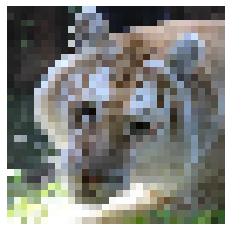

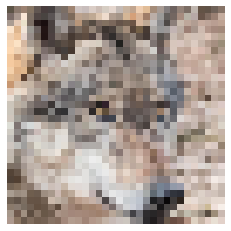

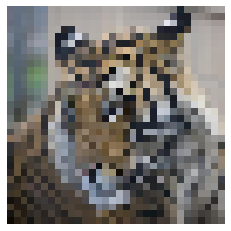

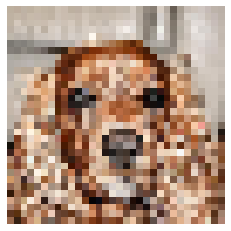

In [ ]:
test_batch_size = 4

images, _ = next(iter(trainloader(batch_size=test_batch_size)))

with torch.no_grad():
    output = model.forward(images)

prob = F.softmax(output,dim=1).data.numpy().squeeze()

for image in images:
  imshow(image)

for i in range(test_batch_size):
    print(f'''
    Tecт {i}
    Вероятности:
    Кот: {prob[i][0]}
    Пес: {prob[i][1]}
    Дикое животное: {prob[i][2]}
    ''')
    